# Predicción de tiros de Kobe Bryant con una red neuronal

**Materia:** Inteligencia Artificial  
**Herramientas:** TensorFlow + Keras sobre Google Colab

---

## 1. Problema seleccionado

**Tarea:** clasificación binaria.

Dado un tiro de Kobe Bryant descrito por su posición en la cancha, el momento del
partido y el tipo de jugada, se busca predecir si el tiro entró (`1`) o no entró (`0`).

**Por qué una red neuronal y no un modelo lineal:** el efecto de una variable no es
constante, sino que depende del valor de las otras. Por ejemplo, el hecho de que un
partido sea de playoffs no modifica el porcentaje de acierto global (44.6% contra
44.5%), pero sí lo modifica en combinación con otras variables: bajo el aro cae de
62.2% a 59.1%, y en los últimos dos minutos del cuarto período cae de 39.0% a 35.2%.

Ese tipo de dependencia se denomina *interacción entre variables*. Una regresión
logística asigna a cada variable un único coeficiente fijo y no puede representarla.
Las capas ocultas de una red neuronal combinan las variables entre sí y permiten
representar interacciones no lineales sin declararlas explícitamente. Esto justifica
la elección de la arquitectura.

## 2. Conjunto de datos

**Fuente:** *Kobe Bryant Shot Selection* (Kaggle).  
**Volumen:** 30.697 registros, 24 variables predictoras y 1 variable objetivo.

La variable objetivo `shot_made_flag` se encuentra vacía en 5.000 registros, que
constituían el conjunto de evaluación de la competencia original y no tienen etiqueta
pública. Esos registros se descartan, y la división entre entrenamiento y prueba se
realiza sobre los 25.697 registros etiquetados.

---
## 3. Importación de librerías

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    log_loss,
)

# Semilla fija: garantiza que la division de datos y la inicializacion de la red
# sean reproducibles en cada ejecucion del notebook.
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

pd.set_option("display.max_columns", 50)
print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.22.0-rc0


---
## 4. Carga del conjunto de datos

Al ejecutar la celda siguiente en Google Colab se abrirá un selector de archivos.
Debe seleccionarse el archivo CSV del conjunto de datos.

In [30]:
import os

CSV_LOCAL = "data 2.csv"  # nombre del archivo si ya esta en el entorno

if os.path.exists(CSV_LOCAL):
    df = pd.read_csv(CSV_LOCAL)
else:
    from google.colab import files
    subido = files.upload()
    nombre_archivo = next(iter(subido))
    df = pd.read_csv(nombre_archivo)

print(f"Registros cargados: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
df.head()

Registros cargados: 30697
Columnas: 25


,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,playoffs,season,seconds_remaining,shot_distance,shot_made_flag,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
0,Jump Shot,Jump Shot,10,20000012,33.9723,167,72,-118.1028,10,1,0,2000-01,27,18,NaN,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,1
1,Jump Shot,Jump Shot,12,20000012,34.0443,-157,0,-118.4268,10,1,0,2000-01,22,15,0.0,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,2
2,Jump Shot,Jump Shot,35,20000012,33.9093,-101,135,-118.3708,7,1,0,2000-01,45,16,1.0,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,3
3,Jump Shot,Jump Shot,43,20000012,33.8693,138,175,-118.1318,6,1,0,2000-01,52,22,0.0,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,4
4,Driving Dunk Shot,Dunk,155,20000012,34.0443,0,0,-118.2698,6,2,0,2000-01,19,0,1.0,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,5


---
## 5. Exploración de los datos

El objetivo de esta sección es responder tres preguntas antes de modelar:

1. ¿Cómo está distribuida la variable objetivo? (determina si hay desbalance de clases)
2. ¿Qué variables presentan valores faltantes?
3. ¿En qué escalas se encuentran las variables numéricas? (determina la necesidad de estandarizar)

In [31]:
print("Distribucion de la variable objetivo 'shot_made_flag':")
print(df["shot_made_flag"].value_counts(dropna=False))
print()

etiquetados = df["shot_made_flag"].notna().sum()
sin_etiqueta = df["shot_made_flag"].isna().sum()
print(f"Registros etiquetados:     {etiquetados}")
print(f"Registros sin etiqueta:    {sin_etiqueta}")

etiq = df[df["shot_made_flag"].notna()]
porc_acierto = etiq["shot_made_flag"].mean() * 100
print(f"\nPorcentaje de acierto general: {porc_acierto:.2f}%")
print(f"Clase mayoritaria (fallados):  {100 - porc_acierto:.2f}%")

Distribucion de la variable objetivo 'shot_made_flag':
shot_made_flag
0.0    14232
1.0    11465
NaN     5000
Name: count, dtype: int64

Registros etiquetados:     25697
Registros sin etiqueta:    5000

Porcentaje de acierto general: 44.62%
Clase mayoritaria (fallados):  55.38%


El conjunto está **casi balanceado** (aproximadamente 55% fallados y 45% convertidos).

Este dato es relevante para la etapa de evaluación: un modelo que predijera siempre
"no entró", sin aprender ningún patrón, obtendría cerca del 55% de *accuracy*. Ese
valor constituye la **línea base** contra la cual debe compararse el modelo. Un
*accuracy* cercano a 55% indicaría que la red no aprendió nada útil.

In [32]:
# Rangos de las variables numericas: justifica la estandarizacion posterior.
numericas = ["loc_x", "loc_y", "shot_distance", "minutes_remaining",
             "seconds_remaining", "period", "playoffs"]

print("Rangos de las variables numericas:\n")
print(df[numericas].agg(["min", "max", "mean", "std"]).T.round(2))

print("\nValores faltantes por columna (solo las que tienen):")
faltantes = df.isna().sum()
print(faltantes[faltantes > 0])

Rangos de las variables numericas:

                     min    max   mean     std
loc_x             -250.0  248.0   7.11  110.12
loc_y              -44.0  791.0  91.11   87.79
shot_distance        0.0   79.0  13.44    9.37
minutes_remaining    0.0   11.0   4.89    3.45
seconds_remaining    0.0   59.0  28.37   17.48
period               1.0    7.0   2.52    1.15
playoffs             0.0    1.0   0.15    0.35

Valores faltantes por columna (solo las que tienen):
shot_made_flag    5000
dtype: int64


Las escalas son marcadamente heterogéneas: `loc_x` toma valores entre -250 y 248,
mientras que `playoffs` toma únicamente 0 o 1.

Una red neuronal calcula la suma ponderada de todas sus entradas. Con pesos iniciales
de magnitud similar, una variable con valores en el orden de las centenas aporta a esa
suma dos órdenes de magnitud más que una variable binaria, **independientemente de su
relevancia predictiva**. Además, la magnitud de la corrección que recibe cada peso
durante el entrenamiento es proporcional al valor de su entrada, por lo que una única
tasa de aprendizaje no resulta adecuada para variables de escalas tan distintas.

Por este motivo las variables continuas se estandarizan en la sección 8.

El único valor faltante del conjunto corresponde a la variable objetivo, en los 5.000
registros ya identificados. Ninguna variable predictora presenta valores faltantes, por
lo que no se requieren técnicas de imputación.

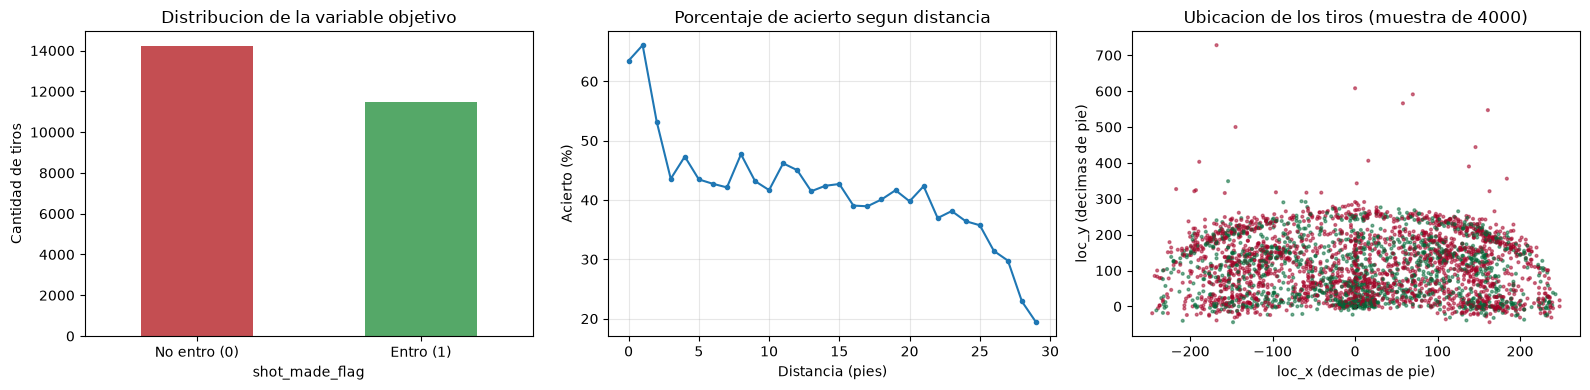

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Grafico 1: distribucion de la variable objetivo
etiq["shot_made_flag"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#c44e52", "#55a868"]
)
axes[0].set_title("Distribucion de la variable objetivo")
axes[0].set_xticklabels(["No entro (0)", "Entro (1)"], rotation=0)
axes[0].set_ylabel("Cantidad de tiros")

# Grafico 2: porcentaje de acierto segun la distancia del tiro
acierto_dist = etiq.groupby("shot_distance")["shot_made_flag"].agg(["mean", "count"])
acierto_dist = acierto_dist[acierto_dist["count"] >= 50]  # se excluye el ruido muestral
axes[1].plot(acierto_dist.index, acierto_dist["mean"] * 100, marker="o", markersize=3)
axes[1].set_title("Porcentaje de acierto segun distancia")
axes[1].set_xlabel("Distancia (pies)")
axes[1].set_ylabel("Acierto (%)")
axes[1].grid(alpha=0.3)

# Grafico 3: ubicacion de los tiros en la cancha
muestra = etiq.sample(4000, random_state=SEED)
axes[2].scatter(muestra["loc_x"], muestra["loc_y"],
                c=muestra["shot_made_flag"], cmap="RdYlGn", s=4, alpha=0.5)
axes[2].set_title("Ubicacion de los tiros (muestra de 4000)")
axes[2].set_xlabel("loc_x (decimas de pie)")
axes[2].set_ylabel("loc_y (decimas de pie)")

plt.tight_layout()
plt.show()

**Observaciones sobre los gráficos:**

- La variable objetivo está casi balanceada, por lo que no se requieren técnicas de
  rebalanceo de clases.
- El porcentaje de acierto decrece con la distancia, con una inflexión en torno a los
  23 pies que corresponde a la línea de tres puntos. La relación no es lineal, lo cual
  refuerza la elección de un modelo no lineal.
- La nube de tiros reproduce la geometría de la cancha, con una concentración elevada
  bajo el aro y sobre la línea de tres puntos.

Para el filtrado del segundo gráfico se exigió un mínimo de 50 observaciones por
distancia. Los porcentajes calculados sobre muestras reducidas presentan una varianza
elevada y producen valores que no son interpretables como patrón.

In [34]:
# Porcentaje de acierto segun el tipo de jugada (variable 'action_type').
# Esta exploracion fundamenta la decision de conservar la variable (seccion 6).
resumen_accion = etiq.groupby("action_type")["shot_made_flag"].agg(["mean", "count"])
resumen_accion = resumen_accion[resumen_accion["count"] >= 100].sort_values("mean")
resumen_accion.columns = ["acierto", "tiros"]

print("Acierto por tipo de jugada (solo jugadas con 100+ tiros):\n")
print(resumen_accion.round(4).to_string())
print(f"\nRango de acierto entre tipos de jugada: "
      f"{resumen_accion['acierto'].min():.2%} a {resumen_accion['acierto'].max():.2%}")

Acierto por tipo de jugada (solo jugadas con 100+ tiros):

                          acierto  tiros
action_type                             
Jump Shot                  0.3269  15836
Tip Shot                   0.3510    151
Layup Shot                 0.3853   2154
Fadeaway Jump Shot         0.5745    872
Turnaround Fadeaway shot   0.5847    366
Turnaround Jump Shot       0.5982    891
Step Back Jump shot        0.6321    106
Reverse Layup Shot         0.6366    333
Pullup Jump shot           0.7239    402
Driving Layup Shot         0.7414   1628
Running Jump Shot          0.7471    779
Jump Bank Shot             0.7751    289
Dunk Shot                  0.7788    217
Driving Dunk Shot          0.9767    257
Slam Dunk Shot             0.9820    334

Rango de acierto entre tipos de jugada: 32.69% a 98.20%


El porcentaje de acierto varía de forma pronunciada entre tipos de jugada. Esta
dispersión indica que `action_type` concentra una proporción considerable de la
información predictiva disponible, y fundamenta la decisión de conservarla pese a su
elevada cardinalidad. La sección 12.4 cuantifica empíricamente su aporte.

---
## 6. Limpieza de los datos

Se aplican los siguientes criterios de descarte:

| Criterio | Columnas | Justificación |
|---|---|---|
| Sin etiqueta | 5.000 filas | No tienen valor en la variable objetivo |
| Variables constantes | `team_id`, `team_name` | Toman un único valor en todo el conjunto |
| Identificadores | `shot_id`, `game_id`, `game_event_id` | Son índices sin contenido predictivo |
| Variables redundantes | `lat`, `lon` | Expresan la misma posición que `loc_x`/`loc_y` |
| Redundancia con otra variable | `matchup`, `game_date` | Ver justificación debajo |

Se **conservan** `action_type` (57 categorías) y `combined_shot_type` (6 categorías),
pese a que la segunda es una agrupación de la primera. La sección 12.4 documenta la
comparación empírica que respalda esta decisión.

In [35]:
# Se conservan unicamente los registros que tienen etiqueta.
datos = df[df["shot_made_flag"].notna()].copy()
datos["shot_made_flag"] = datos["shot_made_flag"].astype(int)
print(f"Registros con etiqueta: {len(datos)}")

# Verificacion de las columnas constantes antes de descartarlas.
print(f"\nValores unicos en team_id:   {datos['team_id'].nunique()}")
print(f"Valores unicos en team_name: {datos['team_name'].nunique()}")

# Verificacion de la redundancia entre lat/lon y loc_x/loc_y.
print(f"\nCorrelacion lon - loc_x: {datos['lon'].corr(datos['loc_x']):.4f}")
print(f"Correlacion lat - loc_y: {datos['lat'].corr(datos['loc_y']):.4f}")

Registros con etiqueta: 25697

Valores unicos en team_id:   1
Valores unicos en team_name: 1

Correlacion lon - loc_x: 1.0000
Correlacion lat - loc_y: -1.0000


In [36]:
columnas_a_descartar = [
    "shot_id", "game_id", "game_event_id",  # identificadores
    "team_id", "team_name",                 # constantes
    "lat", "lon",                           # redundantes con loc_x / loc_y
    "matchup",                              # redundante con 'opponent'
    "game_date",                            # redundante con 'season'
]

datos = datos.drop(columns=columnas_a_descartar)
print(f"Columnas restantes: {datos.shape[1]}")
print(list(datos.columns))

Columnas restantes: 16
['action_type', 'combined_shot_type', 'loc_x', 'loc_y', 'minutes_remaining', 'period', 'playoffs', 'season', 'seconds_remaining', 'shot_distance', 'shot_made_flag', 'shot_type', 'shot_zone_area', 'shot_zone_basic', 'shot_zone_range', 'opponent']


**Justificación de los descartes menos evidentes:**

- `matchup` contiene cadenas como `"LAL @ POR"`. La información del rival ya está
  presente en `opponent`, y la condición de local o visitante está implícita en el
  símbolo `@`. Se descarta para no duplicar información.
- `game_date` es una fecha con más de 1.500 valores distintos. La dimensión temporal
  relevante (la evolución a lo largo de la carrera del jugador) ya está capturada por
  `season`.

La correlación entre `lat`/`lon` y `loc_y`/`loc_x` resulta de magnitud 1 (con signo
negativo en el caso de la latitud, por la orientación del sistema de coordenadas), lo
cual confirma empíricamente la redundancia.

---
## 7. Construcción de variables

Las variables `minutes_remaining` y `seconds_remaining` expresan una misma magnitud
en dos columnas. Se unifican en el tiempo restante total del período, expresado en
segundos, y se agrega un indicador de los últimos dos minutos del período.

El objetivo es entregar a la red la magnitud ya construida, en lugar de requerir que
la deduzca a partir de dos columnas separadas.

In [37]:
datos["tiempo_restante_seg"] = (
    datos["minutes_remaining"] * 60 + datos["seconds_remaining"]
)

# Indicador de los ultimos 2 minutos del periodo.
datos["es_final_periodo"] = (datos["tiempo_restante_seg"] <= 120).astype(int)

datos = datos.drop(columns=["minutes_remaining", "seconds_remaining"])

print(datos[["tiempo_restante_seg", "es_final_periodo"]].describe().round(2))

       tiempo_restante_seg  es_final_periodo
count             25697.00          25697.00
mean                321.52              0.22
std                 208.31              0.41
min                   0.00              0.00
25%                 141.00              0.00
50%                 304.00              0.00
75%                 499.00              0.00
max                 714.00              1.00


---
## 8. Transformación y división de los datos

Esta sección comprende tres operaciones, y **el orden en que se aplican es relevante**.

### 8.1 Codificación de las variables categóricas

Las variables categóricas contienen texto, que la red no puede procesar. Se aplica
codificación *one-hot*: cada categoría se convierte en una columna binaria.

No se utiliza una codificación ordinal (asignar 1, 2, 3, ... a cada categoría) porque
introduciría una relación de orden y de magnitud inexistente entre categorías que son
nominales. Asignar `1` a `POR` y `33` a `WAS` implicaría afirmar que el segundo rival
es treinta y tres veces el primero en alguna dimensión, lo cual carece de sentido.

### 8.2 División en entrenamiento y prueba

Se reserva el 20% de los registros para evaluación. La división se realiza de forma
estratificada, de modo que ambos subconjuntos conserven la proporción original entre
clases.

### 8.3 Estandarización

El `StandardScaler` requiere la media y el desvío estándar de cada variable para
transformarla. Esos estadísticos se calculan **exclusivamente sobre el conjunto de
entrenamiento** (`fit`), y la transformación resultante se aplica luego a ambos
conjuntos (`transform`).

El conjunto de prueba representa observaciones no disponibles durante el
entrenamiento. Si sus valores participaran del cálculo de la media y el desvío, esa
información se incorporaría indirectamente al proceso de entrenamiento, y la métrica
obtenida sobre el conjunto de prueba dejaría de constituir una estimación válida del
desempeño del modelo ante datos nuevos. Esta situación se denomina **fuga de datos**
(*data leakage*), y su consecuencia es una métrica optimista: el valor informado es
superior al desempeño real del modelo ante datos nuevos.

Por este motivo la estandarización se realiza **después** de la división, y el método
`fit` se aplica únicamente al conjunto de entrenamiento.

In [38]:
# Separacion de la variable objetivo respecto de las predictoras.
y = datos["shot_made_flag"].values
X_sin_codificar = datos.drop(columns=["shot_made_flag"])

# Se seleccionan todas las columnas no numericas: son las que requieren codificacion.
categoricas = X_sin_codificar.select_dtypes(exclude="number").columns.tolist()
print("Variables categoricas a codificar:")
for col in categoricas:
    print(f"  {col:22s} -> {X_sin_codificar[col].nunique()} categorias")

Variables categoricas a codificar:
  action_type            -> 55 categorias
  combined_shot_type     -> 6 categorias
  season                 -> 20 categorias
  shot_type              -> 2 categorias
  shot_zone_area         -> 6 categorias
  shot_zone_basic        -> 7 categorias
  shot_zone_range        -> 5 categorias
  opponent               -> 33 categorias


In [39]:
# 8.1 Codificacion one-hot.
X = pd.get_dummies(X_sin_codificar, columns=categoricas, drop_first=False)
X = X.astype(float)

print(f"Columnas antes de codificar:   {X_sin_codificar.shape[1]}")
print(f"Columnas despues de codificar: {X.shape[1]}")

Columnas antes de codificar:   15
Columnas despues de codificar: 141


In [40]:
# 8.2 Division en entrenamiento y prueba. Se realiza ANTES de estandarizar.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,          # conserva la proporcion de clases en ambos subconjuntos
)

print(f"Entrenamiento: {X_train.shape[0]} registros")
print(f"Prueba:        {X_test.shape[0]} registros")
print(f"\nProporcion de clase 1 en entrenamiento: {y_train.mean():.4f}")
print(f"Proporcion de clase 1 en prueba:        {y_test.mean():.4f}")

Entrenamiento: 20557 registros
Prueba:        5140 registros

Proporcion de clase 1 en entrenamiento: 0.4462
Proporcion de clase 1 en prueba:        0.4461


In [41]:
# 8.3 Estandarizacion de las variables continuas.
# Las variables binarias (0/1) y las columnas one-hot ya se encuentran en una escala
# comparable, por lo que no se estandarizan.
continuas = ["loc_x", "loc_y", "shot_distance", "tiempo_restante_seg", "period"]

scaler = StandardScaler()

X_train_esc = X_train.copy()
X_test_esc = X_test.copy()

# fit_transform sobre entrenamiento: calcula los estadisticos y aplica la transformacion.
X_train_esc[continuas] = scaler.fit_transform(X_train[continuas])

# transform sobre prueba: aplica la transformacion ya calculada, sin recalcularla.
X_test_esc[continuas] = scaler.transform(X_test[continuas])

print("Estadisticos aprendidos del conjunto de entrenamiento:\n")
for col, media, desvio in zip(continuas, scaler.mean_, scaler.scale_):
    print(f"  {col:22s} media={media:9.3f}  desvio={desvio:8.3f}")

Estadisticos aprendidos del conjunto de entrenamiento:

  loc_x                  media=    7.239  desvio= 110.091
  loc_y                  media=   90.970  desvio=  87.782
  shot_distance          media=   13.438  desvio=   9.360
  tiempo_restante_seg    media=  321.702  desvio= 208.025
  period                 media=    2.524  desvio=   1.155


In [42]:
# Verificacion del resultado de la estandarizacion.
print("Entrenamiento (media proxima a 0, desvio proximo a 1):")
print(X_train_esc[continuas].agg(["mean", "std"]).T.round(4))

print("\nPrueba (no se espera media exactamente 0: se aplico la escala de entrenamiento):")
print(X_test_esc[continuas].agg(["mean", "std"]).T.round(4))

Entrenamiento (media proxima a 0, desvio proximo a 1):
                     mean  std
loc_x                -0.0  1.0
loc_y                 0.0  1.0
shot_distance        -0.0  1.0
tiempo_restante_seg  -0.0  1.0
period               -0.0  1.0

Prueba (no se espera media exactamente 0: se aplico la escala de entrenamiento):
                       mean     std
loc_x               -0.0041  0.9992
loc_y                0.0164  1.0208
shot_distance        0.0100  1.0154
tiempo_restante_seg -0.0044  1.0068
period              -0.0122  0.9856


La media del conjunto de entrenamiento resulta igual a 0 y su desvío igual a 1, dado
que la transformación se calculó sobre ese conjunto.

En el conjunto de prueba la media no es exactamente 0. Ese resultado es el esperado y
constituye la evidencia de que el procedimiento se aplicó correctamente: al conjunto
de prueba se le aplicó la escala derivada del entrenamiento, sin recalcularla sobre
sus propios valores. Una media exactamente nula en el conjunto de prueba indicaría
que se cometió la fuga de datos descrita en la sección 8.3.

In [43]:
# Conversion a arreglos de NumPy, formato requerido por Keras.
X_train_final = X_train_esc.values.astype("float32")
X_test_final = X_test_esc.values.astype("float32")
y_train_final = y_train.astype("float32")
y_test_final = y_test.astype("float32")

N_FEATURES = X_train_final.shape[1]

print("Datos preparados:\n")
print(f"  X_train: {X_train_final.shape}")
print(f"  X_test:  {X_test_final.shape}")
print(f"  y_train: {y_train_final.shape}")
print(f"  y_test:  {y_test_final.shape}")
print(f"\n  Variables de entrada de la red: {N_FEATURES}")
print(f"  Valores faltantes restantes:    {np.isnan(X_train_final).sum()}")

Datos preparados:

  X_train: (20557, 141)
  X_test:  (5140, 141)
  y_train: (20557,)
  y_test:  (5140,)

  Variables de entrada de la red: 141
  Valores faltantes restantes:    0


---
## 9. Diseño de la arquitectura de la red

### Estructura seleccionada

| Capa | Neuronas | Activación | Función |
|---|---|---|---|
| Entrada | 141 | — | Una por variable de entrada |
| Oculta | 64 | ReLU | Combina las variables entre sí |
| Salida | 1 | Sigmoide | Probabilidad de que el tiro haya entrado |

### Justificación de cada decisión

**Una capa oculta.** La capa oculta combina las variables de entrada entre sí, lo cual
permite representar interacciones: situaciones en las que el efecto de una variable
depende del valor de otra. Se evaluaron arquitecturas de mayor capacidad (sección 12.4)
y no mejoraron el desempeño, por lo que se conserva la más simple.

**64 neuronas.** El valor se encuentra por debajo de las 141 variables de entrada, lo
cual obliga a la capa a resumir la información en lugar de replicarla. Con 141 neuronas
o más, la capa podría reproducir la entrada sin transformarla.

**Activación ReLU en la capa oculta.** `ReLU(z) = max(0, z)`: convierte en cero los
valores negativos y deja pasar sin cambios los positivos.

Es la fuente de la no linealidad del modelo. Sin una función de activación no lineal, la
composición de capas equivale a una única transformación lineal: si `h = W1 · x` y
`s = W2 · h`, entonces `s = (W2 · W1) · x`, es decir, una sola matriz. En ese caso la red
no podría representar interacciones entre variables.

**Activación sigmoide en la capa de salida.** `sigmoide(z) = 1 / (1 + e^-z)`. Comprime
cualquier valor real al intervalo (0, 1), lo cual permite leer la salida como la
probabilidad de que el tiro haya entrado. Es la activación correspondiente a una tarea de
clasificación binaria con una única neurona de salida.

**Sin regularización por *dropout*.** Se evaluó su incorporación (sección 12.4) y no
produjo mejora: la detención temprana descrita en la sección 10 resulta suficiente para
controlar el sobreajuste en este conjunto. Se omite para no agregar complejidad sin
beneficio medible.

**Función de pérdida: entropía cruzada binaria.** Es la función de pérdida
correspondiente a una salida sigmoide en clasificación binaria. Penaliza en mayor medida
las predicciones que son simultáneamente incorrectas y confiadas: sobre un caso de clase
1, una predicción de 0,01 recibe una pérdida de 4,61, mientras que una predicción de 0,36
recibe 1,03.

**Optimizador: Adam**, con tasa de aprendizaje 0,001. Determina cuánto se corrige cada
peso después de cada error.

In [44]:
def construir_modelo(n_features, neuronas=(64,), dropouts=(0.0,),
                     learning_rate=0.001):
    capas = [keras.layers.Input(shape=(n_features,), name="entrada")]

    for i, (n, d) in enumerate(zip(neuronas, dropouts), start=1):
        capas.append(keras.layers.Dense(n, activation="relu", name=f"oculta_{i}"))
        if d > 0:
            capas.append(keras.layers.Dropout(d, name=f"dropout_{i}"))

    capas.append(keras.layers.Dense(1, activation="sigmoid", name="salida"))

    modelo = keras.Sequential(capas, name="red_tiros_kobe")
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return modelo


modelo = construir_modelo(N_FEATURES)
modelo.summary()

Model: "red_tiros_kobe"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         9,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,153 (35.75 KB)

 Trainable params: 9,153 (35.75 KB)

 Non-trainable params: 0 (0.00 B)

**Lectura del resumen del modelo.** La cantidad de parámetros de cada capa densa
corresponde a `(entradas x neuronas) + neuronas`, donde el segundo término son los
sesgos:

```
oculta_1:  141 x 64 + 64 = 9.088
salida:     64 x  1 +  1 =    65
                          -------
                            9.153
```

Esos 9.153 valores son los **pesos y sesgos**: constituyen la totalidad de lo que el
modelo aprende. Se inicializan de forma aleatoria y se corrigen durante el entrenamiento.

La relación entre parámetros y registros utilizados para el ajuste es de 9.153 a 16.445,
es decir, aproximadamente 1,8 observaciones por parámetro. Esta proporción es baja y
justifica el uso de detención temprana.

---
## 10. Entrenamiento del modelo

### Parámetros establecidos

| Parámetro | Valor | Justificación |
|---|---|---|
| `epochs` | 200 (máximo) | Límite superior; la detención temprana define el valor efectivo |
| `batch_size` | 256 | Cantidad de registros procesados antes de cada corrección de pesos |
| `validation_split` | 0.2 | Porción del entrenamiento reservada para monitorear el sobreajuste |
| `EarlyStopping` | `patience=15` | Detiene el entrenamiento cuando la pérdida de validación deja de mejorar |

### Sobre el conjunto de validación

El entrenamiento utiliza **tres** subconjuntos de datos, con funciones distintas:

| Subconjunto | Registros | % del total | Función |
|---|---|---|---|
| Entrenamiento | 16.445 | 64% | Ajuste de los pesos |
| Validación | 4.111 | 16% | Decisión de cuándo detener el entrenamiento |
| Prueba | 5.140 | 20% | Evaluación final, utilizada una única vez |

El conjunto de validación es necesario porque la detención temprana es, en sí misma,
una decisión tomada en función de los datos. Si esa decisión se tomara observando el
conjunto de prueba, dicho conjunto dejaría de ser independiente y la métrica final
perdería validez. El conjunto de prueba se utiliza exclusivamente en la sección 11,
una vez concluido el entrenamiento.

### Sobre la detención temprana

`EarlyStopping` monitorea la pérdida sobre el conjunto de validación. Mientras esa
pérdida desciende, el modelo mejora su capacidad de generalización. Cuando comienza a
ascender mientras la pérdida de entrenamiento continúa descendiendo, el modelo está
memorizando los datos de entrenamiento en lugar de aprender patrones generalizables:
ese es el **sobreajuste**.

El parámetro `patience=15` establece que el entrenamiento se detiene luego de 15
épocas consecutivas sin mejora. `restore_best_weights=True` recupera los pesos
correspondientes a la época de menor pérdida de validación, descartando las épocas
posteriores.

In [45]:
detencion_temprana = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1,
)

historial = modelo.fit(
    X_train_final, y_train_final,
    validation_split=0.20,
    epochs=200,
    batch_size=256,
    callbacks=[detencion_temprana],
    verbose=2,
)

epocas_ejecutadas = len(historial.history["loss"])
mejor_epoca = int(np.argmin(historial.history["val_loss"])) + 1

print(f"\nEpocas ejecutadas: {epocas_ejecutadas}")
print(f"Mejor epoca (menor val_loss): {mejor_epoca}")
print(f"Menor val_loss alcanzado: {min(historial.history['val_loss']):.4f}")
print(f"loss de entrenamiento en esa epoca: {historial.history['loss'][mejor_epoca - 1]:.4f}")

Epoch 1/200
65/65 - 1s - 21ms/step - accuracy: 0.6060 - auc: 0.6285 - loss: 0.6589 - val_accuracy: 0.6581 - val_auc: 0.6762 - val_loss: 0.6352
Epoch 2/200
65/65 - 0s - 2ms/step - accuracy: 0.6714 - auc: 0.6873 - loss: 0.6219 - val_accuracy: 0.6829 - val_auc: 0.6880 - val_loss: 0.6168
Epoch 3/200
65/65 - 0s - 2ms/step - accuracy: 0.6814 - auc: 0.7037 - loss: 0.6078 - val_accuracy: 0.6812 - val_auc: 0.6885 - val_loss: 0.6125
Epoch 4/200
65/65 - 0s - 2ms/step - accuracy: 0.6831 - auc: 0.7119 - loss: 0.6023 - val_accuracy: 0.6821 - val_auc: 0.6894 - val_loss: 0.6117
Epoch 5/200
65/65 - 0s - 2ms/step - accuracy: 0.6844 - auc: 0.7166 - loss: 0.5991 - val_accuracy: 0.6824 - val_auc: 0.6899 - val_loss: 0.6115
Epoch 6/200
65/65 - 0s - 2ms/step - accuracy: 0.6849 - auc: 0.7202 - loss: 0.5966 - val_accuracy: 0.6826 - val_auc: 0.6901 - val_loss: 0.6115
Epoch 7/200
65/65 - 0s - 2ms/step - accuracy: 0.6856 - auc: 0.7235 - loss: 0.5945 - val_accuracy: 0.6826 - val_auc: 0.6904 - val_loss: 0.6116
Epoch

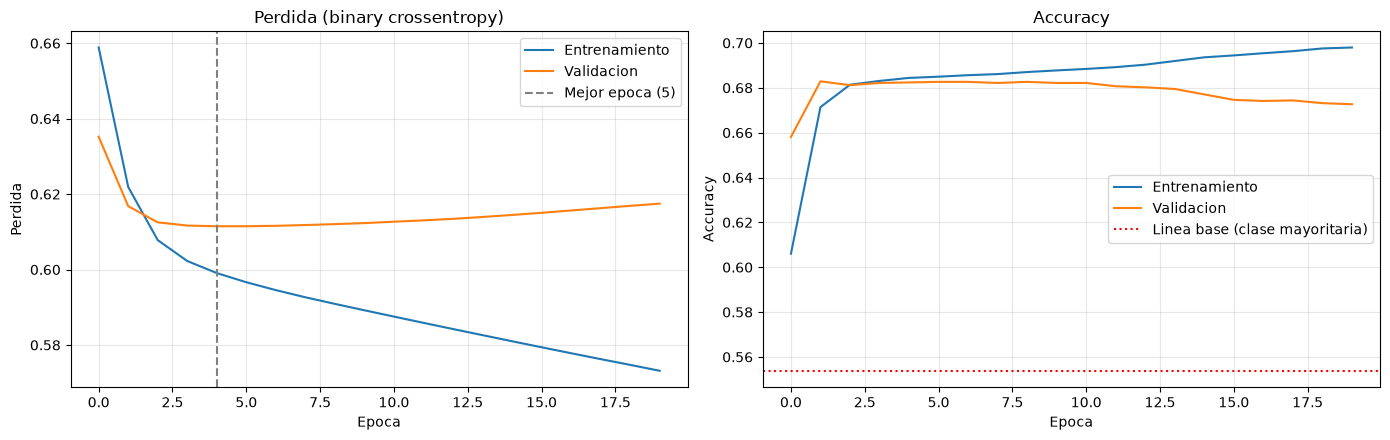

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Curvas de perdida: el grafico principal para diagnosticar sobreajuste.
axes[0].plot(historial.history["loss"], label="Entrenamiento")
axes[0].plot(historial.history["val_loss"], label="Validacion")
axes[0].axvline(mejor_epoca - 1, color="gray", linestyle="--",
                label=f"Mejor epoca ({mejor_epoca})")
axes[0].set_title("Perdida (binary crossentropy)")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Perdida")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Curvas de accuracy.
axes[1].plot(historial.history["accuracy"], label="Entrenamiento")
axes[1].plot(historial.history["val_accuracy"], label="Validacion")
axes[1].axhline(1 - y_train_final.mean(), color="red", linestyle=":",
                label="Linea base (clase mayoritaria)")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Lectura de las curvas.** El gráfico de pérdida es el instrumento de diagnóstico del
sobreajuste. Los tres comportamientos posibles son:

| Comportamiento observado | Diagnóstico |
|---|---|
| Ambas curvas descienden y se estabilizan juntas | Entrenamiento adecuado |
| Entrenamiento desciende, validación asciende | Sobreajuste |
| Ambas permanecen altas | Subajuste: el modelo carece de capacidad suficiente |

La línea vertical marca la época de menor pérdida de validación, que es la que
`restore_best_weights` recupera. Las épocas posteriores a esa marca corresponden al
período en que el modelo comenzó a memorizar, y sus pesos fueron descartados.

El entrenamiento converge en pocas épocas. Esto es coherente con la naturaleza del
problema: la señal disponible en las variables se agota rápidamente, y a partir de ese
punto el descenso de la pérdida de entrenamiento se produce por memorización y no por
aprendizaje de patrones generalizables.

En el gráfico de *accuracy*, la línea horizontal roja indica el valor que obtendría un
modelo que predijera siempre la clase mayoritaria. La distancia entre las curvas y esa
línea representa el aprendizaje efectivo del modelo.

---
## 11. Evaluación de los resultados

### Selección de las métricas

Se reportan cinco métricas, dado que cada una responde a una pregunta distinta y
ninguna resulta suficiente por sí sola.

| Métrica | Pregunta que responde | Fórmula |
|---|---|---|
| *Accuracy* | ¿Qué proporción del total se clasificó correctamente? | `(VP + VN) / total` |
| *Precision* | De los tiros predichos como convertidos, ¿cuántos lo fueron? | `VP / (VP + FP)` |
| *Recall* | De los tiros efectivamente convertidos, ¿cuántos se detectaron? | `VP / (VP + FN)` |
| *F1* | Media armónica entre *precision* y *recall* | `2PR / (P + R)` |
| ROC-AUC | ¿Qué capacidad de ordenamiento tiene el modelo? | Área bajo la curva ROC |

donde VP = verdaderos positivos, VN = verdaderos negativos, FP = falsos positivos y
FN = falsos negativos.

**Por qué el *accuracy* resulta insuficiente.** El conjunto presenta un 55,4% de tiros
fallados. Un modelo que predijera siempre "no entró" obtendría ese mismo 55,4% de
*accuracy* sin haber aprendido ningún patrón. El *accuracy* tampoco distingue el tipo
de error cometido: un modelo con muchos falsos positivos y otro con muchos falsos
negativos pueden presentar valores idénticos de *accuracy* y comportamientos
completamente distintos.

**Por qué se incluye ROC-AUC.** Las cuatro primeras métricas se calculan sobre
decisiones binarias, y por lo tanto dependen del umbral elegido. ROC-AUC se calcula
sobre las probabilidades y es independiente del umbral: mide la probabilidad de que el
modelo asigne una probabilidad mayor a un tiro convertido tomado al azar que a un tiro
fallado tomado al azar. Un valor de 0,5 equivale a una asignación aleatoria.

In [47]:
# Prediccion sobre el conjunto de prueba. La red devuelve probabilidades.
y_prob = modelo.predict(X_test_final, verbose=0).ravel()

UMBRAL = 0.50
y_pred = (y_prob >= UMBRAL).astype(int)

print("Primeras 10 probabilidades predichas:")
print(np.round(y_prob[:10], 4))
print("\nDecisiones con umbral 0.50:")
print(y_pred[:10])
print("\nValor real:")
print(y_test[:10])

Primeras 10 probabilidades predichas:
[0.6941 0.2654 0.2543 0.3072 0.3201 0.7082 0.3342 0.8921 0.3074 0.8594]

Decisiones con umbral 0.50:
[1 0 0 0 0 1 0 1 0 1]

Valor real:
[0 0 0 0 0 0 0 0 0 1]


In [48]:
# Linea base: modelo que predice siempre la clase mayoritaria.
accuracy_base = max(y_test.mean(), 1 - y_test.mean())

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
perdida_test = log_loss(y_test, y_prob)

print("=" * 58)
print("METRICAS SOBRE EL CONJUNTO DE PRUEBA")
print("=" * 58)
print(f"  Accuracy          {acc:.4f}   ({acc * 100:.2f}%)")
print(f"  Precision         {prec:.4f}")
print(f"  Recall            {rec:.4f}")
print(f"  F1-score          {f1:.4f}")
print(f"  ROC-AUC           {auc:.4f}")
print(f"  Log loss          {perdida_test:.4f}")
print("-" * 58)
print(f"  Linea base        {accuracy_base:.4f}   (predecir siempre la clase mayoritaria)")
print(f"  Mejora sobre base {(acc - accuracy_base) * 100:+.2f} puntos porcentuales")
print("=" * 58)

METRICAS SOBRE EL CONJUNTO DE PRUEBA
  Accuracy          0.6751   (67.51%)
  Precision         0.7089
  Recall            0.4610
  F1-score          0.5587
  ROC-AUC           0.6905
  Log loss          0.6141
----------------------------------------------------------
  Linea base        0.5539   (predecir siempre la clase mayoritaria)
  Mejora sobre base +12.12 puntos porcentuales


In [49]:
print("Reporte de clasificacion:\n")
print(classification_report(
    y_test, y_pred,
    target_names=["No entro (0)", "Entro (1)"],
    digits=4,
))

Reporte de clasificacion:

              precision    recall  f1-score   support

No entro (0)     0.6613    0.8476    0.7429      2847
   Entro (1)     0.7089    0.4610    0.5587      2293

    accuracy                         0.6751      5140
   macro avg     0.6851    0.6543    0.6508      5140
weighted avg     0.6825    0.6751    0.6607      5140



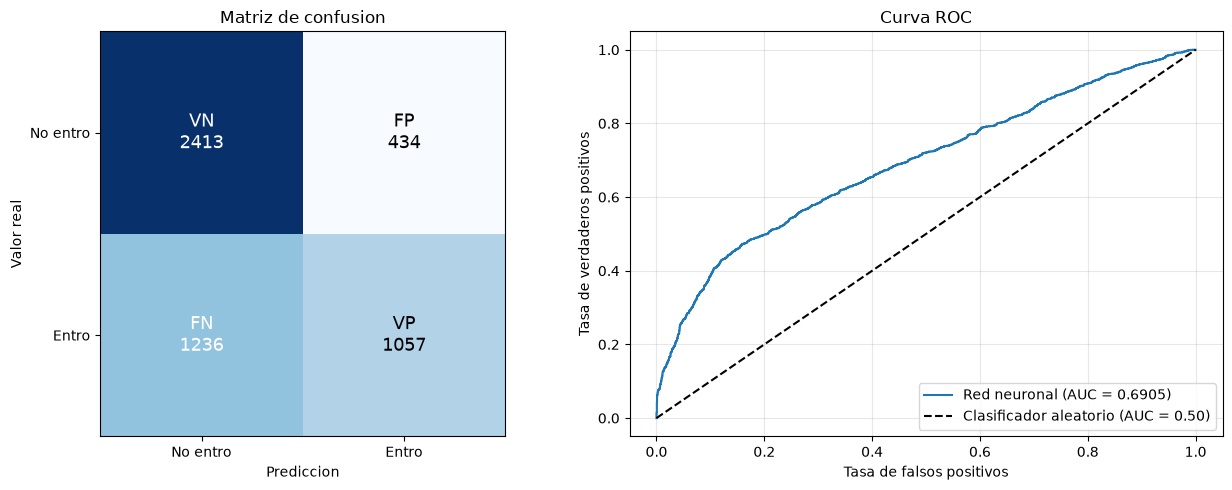

Verdaderos negativos (VN):  2413  - fallo y se predijo que fallaba
Falsos positivos     (FP):   434  - fallo pero se predijo que entraba
Falsos negativos     (FN):  1236  - entro pero se predijo que fallaba
Verdaderos positivos (VP):  1057  - entro y se predijo que entraba


In [50]:
matriz = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = matriz.ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de confusion.
axes[0].imshow(matriz, cmap="Blues")
axes[0].set_title("Matriz de confusion")
axes[0].set_xlabel("Prediccion")
axes[0].set_ylabel("Valor real")
axes[0].set_xticks([0, 1], ["No entro", "Entro"])
axes[0].set_yticks([0, 1], ["No entro", "Entro"])

etiquetas = [[f"VN\n{vn}", f"FP\n{fp}"], [f"FN\n{fn}", f"VP\n{vp}"]]
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, etiquetas[i][j], ha="center", va="center",
                     fontsize=13,
                     color="white" if matriz[i, j] > matriz.max() / 2 else "black")

# Curva ROC.
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"Red neuronal (AUC = {auc:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Clasificador aleatorio (AUC = 0.50)")
axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Verdaderos negativos (VN): {vn:5d}  - fallo y se predijo que fallaba")
print(f"Falsos positivos     (FP): {fp:5d}  - fallo pero se predijo que entraba")
print(f"Falsos negativos     (FN): {fn:5d}  - entro pero se predijo que fallaba")
print(f"Verdaderos positivos (VP): {vp:5d}  - entro y se predijo que entraba")

**Lectura de la matriz de confusión.** La asimetría entre los dos tipos de error es el
resultado más relevante de esta sección: la cantidad de falsos negativos supera de forma
considerable a la de falsos positivos.

El modelo es **conservador**: cuando afirma que un tiro entró, acierta con una
frecuencia elevada (*precision* alta), pero omite una proporción importante de los tiros
que efectivamente entraron (*recall* bajo). Este comportamiento no es un defecto de la
implementación, sino la consecuencia directa de dos factores:

1. La clase mayoritaria es "no entró" (55,4%), de modo que la predicción negativa es la
   apuesta más segura ante la incertidumbre.
2. La función de pérdida penaliza las predicciones confiadas y erradas, lo cual induce
   al modelo a mantenerse próximo al valor esperado cuando la evidencia es ambigua.

La sección 12.2 muestra que este comportamiento puede modificarse desplazando el umbral
de decisión, sin reentrenar el modelo.

---
## 12. Interpretación de las predicciones

Esta sección analiza el comportamiento del modelo más allá de los valores agregados de
las métricas.

### 12.1 Distribución de las probabilidades predichas

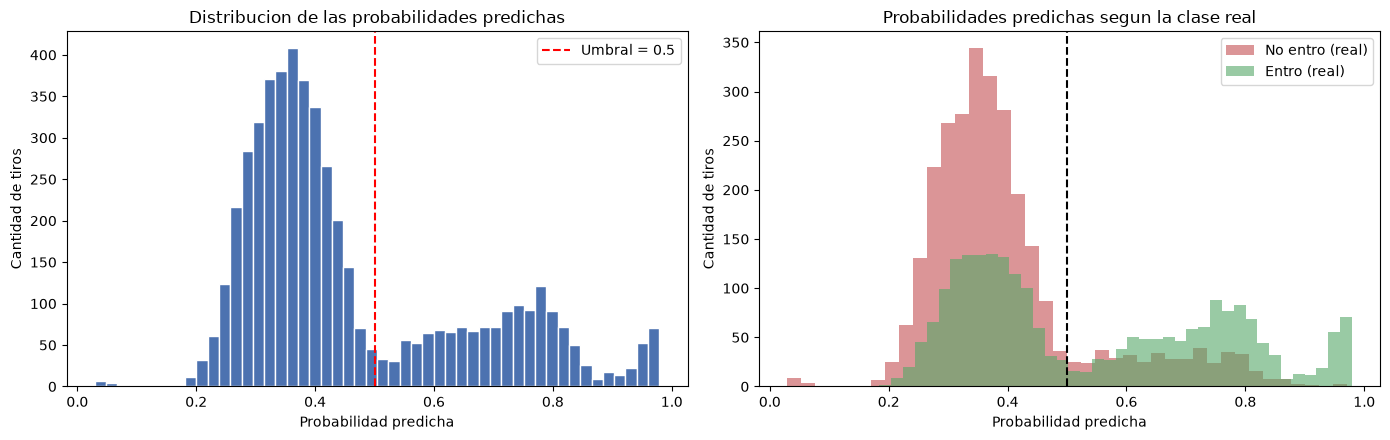

Rango de probabilidades: 0.0294 a 0.9790
Proporcion en la zona de incertidumbre (0.40 - 0.60): 21.9%

Probabilidad media asignada a los tiros que NO entraron: 0.3969
Probabilidad media asignada a los tiros que SI entraron:  0.5394
Separacion entre ambas medias: 0.1425


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(y_prob, bins=50, color="#4c72b0", edgecolor="white")
axes[0].axvline(UMBRAL, color="red", linestyle="--", label=f"Umbral = {UMBRAL}")
axes[0].set_title("Distribucion de las probabilidades predichas")
axes[0].set_xlabel("Probabilidad predicha")
axes[0].set_ylabel("Cantidad de tiros")
axes[0].legend()

axes[1].hist(y_prob[y_test == 0], bins=40, alpha=0.6, label="No entro (real)", color="#c44e52")
axes[1].hist(y_prob[y_test == 1], bins=40, alpha=0.6, label="Entro (real)", color="#55a868")
axes[1].axvline(UMBRAL, color="black", linestyle="--")
axes[1].set_title("Probabilidades predichas segun la clase real")
axes[1].set_xlabel("Probabilidad predicha")
axes[1].set_ylabel("Cantidad de tiros")
axes[1].legend()

plt.tight_layout()
plt.show()

zona_incierta = ((y_prob > 0.40) & (y_prob < 0.60)).mean()
print(f"Rango de probabilidades: {y_prob.min():.4f} a {y_prob.max():.4f}")
print(f"Proporcion en la zona de incertidumbre (0.40 - 0.60): {zona_incierta * 100:.1f}%")
print(f"\nProbabilidad media asignada a los tiros que NO entraron: {y_prob[y_test == 0].mean():.4f}")
print(f"Probabilidad media asignada a los tiros que SI entraron:  {y_prob[y_test == 1].mean():.4f}")
print(f"Separacion entre ambas medias: {y_prob[y_test == 1].mean() - y_prob[y_test == 0].mean():.4f}")

El modelo asigna en promedio una probabilidad mayor a los tiros que efectivamente
entraron, lo cual confirma que la señal aprendida es real. Sin embargo, la separación
entre ambas medias es moderada y las dos distribuciones se superponen de forma
considerable.

**Esa superposición es la causa directa del límite observado en las métricas.** Para
una proporción relevante de los tiros, las variables disponibles no permiten distinguir
el resultado. El modelo expresa esa ambigüedad asignando probabilidades intermedias,
que es la respuesta correcta ante información insuficiente.

### 12.2 Efecto del umbral de decisión

In [52]:
print("Efecto del umbral de decision:\n")
print(f"{'Umbral':>8} {'Accuracy':>10} {'Precision':>11} {'Recall':>9} {'F1':>9} {'Predice 1':>11}")
print("-" * 62)

filas_umbral = []
for u in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    pred_u = (y_prob >= u).astype(int)
    if pred_u.sum() == 0:
        continue
    fila = {
        "umbral": u,
        "accuracy": accuracy_score(y_test, pred_u),
        "precision": precision_score(y_test, pred_u, zero_division=0),
        "recall": recall_score(y_test, pred_u),
        "f1": f1_score(y_test, pred_u),
        "predice_1": pred_u.mean(),
    }
    filas_umbral.append(fila)
    print(f"{u:>8.2f} {fila['accuracy']:>10.4f} {fila['precision']:>11.4f} "
          f"{fila['recall']:>9.4f} {fila['f1']:>9.4f} {fila['predice_1'] * 100:>10.1f}%")

tabla_umbral = pd.DataFrame(filas_umbral)
mejor_f1 = tabla_umbral.loc[tabla_umbral["f1"].idxmax()]
mejor_acc = tabla_umbral.loc[tabla_umbral["accuracy"].idxmax()]
print("-" * 62)
print(f"Umbral que maximiza F1:       {mejor_f1['umbral']:.2f}  (F1 = {mejor_f1['f1']:.4f})")
print(f"Umbral que maximiza accuracy: {mejor_acc['umbral']:.2f}  (acc = {mejor_acc['accuracy']:.4f})")

Efecto del umbral de decision:

  Umbral   Accuracy   Precision    Recall        F1   Predice 1
--------------------------------------------------------------
    0.30     0.5179      0.4786    0.9036    0.6258       84.2%
    0.35     0.5757      0.5166    0.7588    0.6147       65.5%
    0.40     0.6399      0.5933    0.6127    0.6029       46.1%
    0.45     0.6652      0.6669    0.4985    0.5705       33.3%
    0.50     0.6751      0.7089    0.4610    0.5587       29.0%
    0.55     0.6774      0.7276    0.4427    0.5504       27.1%
    0.60     0.6757      0.7520    0.4073    0.5284       24.2%
    0.65     0.6617      0.7628    0.3506    0.4804       20.5%
    0.70     0.6514      0.7843    0.3014    0.4354       17.1%
--------------------------------------------------------------
Umbral que maximiza F1:       0.30  (F1 = 0.6258)
Umbral que maximiza accuracy: 0.55  (acc = 0.6774)


La tabla evidencia el intercambio entre *precision* y *recall*: ambas métricas se
desplazan en direcciones opuestas al modificar el umbral. Al elevarlo, el modelo afirma
"entró" con menor frecuencia y mayor acierto; al reducirlo, detecta más tiros
convertidos a costa de incrementar los falsos positivos.

Resulta relevante que **el umbral que maximiza el *accuracy* no es el que maximiza el
F1**. Esto confirma que la elección del umbral no es un problema técnico con una
respuesta única, sino una decisión que depende de la métrica que se considere
prioritaria, y por lo tanto del uso previsto del modelo.

Para el presente trabajo se conserva el umbral de 0,50. El problema es descriptivo y
ninguno de los dos tipos de error tiene un costo asociado superior al otro, por lo que
no existe fundamento para desplazarlo. Se documenta explícitamente que se trata de una
decisión adoptada y no de un valor impuesto por el método.

### 12.3 Desempeño según la zona de la cancha

In [53]:
# Se recuperan las columnas originales del conjunto de prueba a traves de su indice.
test_original = datos.loc[X_test.index].copy()
test_original["prob_predicha"] = y_prob
test_original["prediccion"] = y_pred
test_original["acierto"] = (y_pred == y_test).astype(int)

resumen_zona = test_original.groupby("shot_zone_basic").agg(
    tiros=("acierto", "size"),
    acierto_real=("shot_made_flag", "mean"),
    prob_media=("prob_predicha", "mean"),
    accuracy_modelo=("acierto", "mean"),
).sort_values("tiros", ascending=False)

resumen_zona["error_calibracion"] = (
    resumen_zona["prob_media"] - resumen_zona["acierto_real"]
)
resumen_zona = resumen_zona[resumen_zona["tiros"] >= 30]  # se excluye el ruido muestral

print("Desempenio por zona de la cancha (solo zonas con 30+ tiros en prueba):\n")
print(resumen_zona.round(4).to_string())

Desempenio por zona de la cancha (solo zonas con 30+ tiros en prueba):

                       tiros  acierto_real  prob_media  accuracy_modelo  error_calibracion
shot_zone_basic                                                                           
Mid-Range               2086        0.4008      0.4244           0.6486             0.0236
Restricted Area         1211        0.6185      0.6243           0.7102             0.0058
Above the Break 3        969        0.3282      0.3489           0.6718             0.0208
In The Paint (Non-RA)    736        0.4660      0.4646           0.7024            -0.0014
Right Corner 3            74        0.3243      0.3756           0.6351             0.0513
Left Corner 3             49        0.4694      0.3385           0.5510            -0.1309


La columna `error_calibracion` compara la probabilidad media predicha con el porcentaje
de acierto real de cada zona. Los valores próximos a cero indican que el modelo estima
correctamente la probabilidad **agregada** de cada zona, aun cuando no acierte el
resultado **individual** de cada tiro.

Esta distinción es central para interpretar el modelo: su utilidad no reside en
determinar el resultado de un tiro particular, sino en estimar correctamente la
probabilidad de conversión de una situación de juego.

El *accuracy* por zona es superior en aquellas cuyo porcentaje de acierto real se aparta
de 0,50, y se degrada en las zonas intermedias. Esto es esperable: cuando la
probabilidad real se aproxima a 0,50, ninguna decisión binaria puede ser
sistemáticamente correcta.

**Advertencia sobre el tamaño de muestra.** La zona `Left Corner 3` presenta el mayor
error de calibración de la tabla, pero cuenta con menos de 50 tiros en el conjunto de
prueba. Con esa cantidad de observaciones, la variación de unos pocos resultados
modifica el porcentaje en varios puntos, de modo que el valor no es interpretable como
un sesgo sistemático del modelo. Las zonas con más de 700 tiros presentan errores de
calibración inferiores a 0,04, y son las que admiten una lectura confiable.

### 12.4 Verificación empírica de las decisiones de diseño

Las decisiones sobre qué variables conservar y qué arquitectura utilizar se verifican
de forma empírica, en lugar de fundamentarse únicamente en criterios generales. La
celda siguiente entrena cuatro variantes y compara sus resultados sobre el mismo
conjunto de prueba.

In [54]:
def evaluar_variante(nombre, usar_action_type, neuronas, dropouts, learning_rate=0.001):
    """Entrena una variante con el mismo procedimiento y devuelve sus metricas."""
    np.random.seed(SEED)
    tf.random.set_seed(SEED)
    keras.utils.set_random_seed(SEED)

    base = datos if usar_action_type else datos.drop(columns=["action_type"])

    y_v = base["shot_made_flag"].values
    Xs_v = base.drop(columns=["shot_made_flag"])
    cats_v = Xs_v.select_dtypes(exclude="number").columns.tolist()
    X_v = pd.get_dummies(Xs_v, columns=cats_v, drop_first=False).astype(float)

    Xtr, Xte, ytr, yte = train_test_split(
        X_v, y_v, test_size=0.20, random_state=SEED, stratify=y_v
    )

    sc = StandardScaler()
    Xtr_e, Xte_e = Xtr.copy(), Xte.copy()
    Xtr_e[continuas] = sc.fit_transform(Xtr[continuas])
    Xte_e[continuas] = sc.transform(Xte[continuas])

    m = construir_modelo(Xtr_e.shape[1], neuronas, dropouts, learning_rate)
    es = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    )
    h = m.fit(Xtr_e.values.astype("float32"), ytr.astype("float32"),
              validation_split=0.20, epochs=200, batch_size=256,
              callbacks=[es], verbose=0)

    prob = m.predict(Xte_e.values.astype("float32"), verbose=0).ravel()
    pred = (prob >= 0.50).astype(int)

    return {
        "variante": nombre,
        "features": Xtr_e.shape[1],
        "params": m.count_params(),
        "epocas": len(h.history["loss"]),
        "accuracy": round(accuracy_score(yte, pred), 4),
        "f1": round(f1_score(yte, pred), 4),
        "roc_auc": round(roc_auc_score(yte, prob), 4),
        "log_loss": round(log_loss(yte, prob), 4),
    }


variantes = [
    evaluar_variante("1. Sin action_type, 64",        False, (64,),    (0.0,)),
    evaluar_variante("2. Con action_type, 64",        True,  (64,),    (0.0,)),
    evaluar_variante("3. Con action_type, 64+dropout", True, (64,),    (0.30,)),
    evaluar_variante("4. Con action_type, 64-32",     True,  (64, 32), (0.0, 0.0)),
]

comparacion = pd.DataFrame(variantes)
print(comparacion.to_string(index=False))

                      variante  features  params  epocas  accuracy     f1  roc_auc  log_loss
        1. Sin action_type, 64        86    5633      22    0.6051 0.4454   0.6176    0.6547
        2. Con action_type, 64       141    9153      20    0.6751 0.5587   0.6905    0.6141
3. Con action_type, 64+dropout       141    9153      28    0.6745 0.5542   0.6880    0.6141
     4. Con action_type, 64-32       141   11201      18    0.6745 0.5626   0.6866    0.6173


**Conclusión de la comparación.** Los resultados permiten separar el efecto de dos
decisiones de diseño distintas.

**1. Conservar `action_type` produce una mejora sustancial.** La diferencia entre la
variante 1 y la 2 es de varios puntos porcentuales tanto en *accuracy* como en ROC-AUC.
Una versión preliminar de este trabajo descartaba esa variable por su elevada
cardinalidad (57 categorías), con el criterio de mantener el modelo simple. La medición
mostró que ese criterio era incorrecto: la variable concentra una parte considerable de
la información predictiva disponible, lo cual es coherente con la dispersión del
porcentaje de acierto entre tipos de jugada observada en la sección 5.

**2. Agregar capacidad al modelo no produce mejora apreciable.** Las variantes 2, 3 y 4
presentan resultados equivalentes entre sí, pese a que incorporan regularización por
*dropout* (variante 3) o una segunda capa oculta (variante 4). Ninguna de las dos
adiciones mejora el desempeño sobre el conjunto de prueba.

Por ese motivo el modelo final utiliza la configuración más simple de las evaluadas: una
única capa oculta de 64 neuronas, sin *dropout*. La decisión no se fundamenta en un
criterio general sobre la simplicidad, sino en la medición registrada en esta tabla.

**Conclusión metodológica: el factor determinante del desempeño fue la información
suministrada al modelo, no la capacidad de la red.**

### 12.5 Ejemplos concretos de predicciones

In [55]:
cols_muestra = ["action_type", "shot_zone_basic", "shot_distance",
                "period", "tiempo_restante_seg", "shot_made_flag", "prob_predicha"]

aciertos = test_original[test_original["acierto"] == 1].copy()
errores = test_original[test_original["acierto"] == 0].copy()

aciertos["confianza"] = (aciertos["prob_predicha"] - 0.5).abs()
errores["confianza"] = (errores["prob_predicha"] - 0.5).abs()

print("PREDICCIONES CORRECTAS CON MAYOR CONFIANZA:\n")
print(aciertos.nlargest(5, "confianza")[cols_muestra].round(4).to_string(index=False))

print("\n\nPREDICCIONES ERRADAS CON MAYOR CONFIANZA:\n")
print(errores.nlargest(5, "confianza")[cols_muestra].round(4).to_string(index=False))

PREDICCIONES CORRECTAS CON MAYOR CONFIANZA:

   action_type shot_zone_basic  shot_distance  period  tiempo_restante_seg  shot_made_flag  prob_predicha
Slam Dunk Shot Restricted Area              0       3                  358               1         0.9790
Slam Dunk Shot Restricted Area              0       1                  536               1         0.9790
Slam Dunk Shot Restricted Area              0       2                  354               1         0.9787
Slam Dunk Shot Restricted Area              0       2                  189               1         0.9785
Slam Dunk Shot Restricted Area              0       1                  708               1         0.9778


PREDICCIONES ERRADAS CON MAYOR CONFIANZA:

           action_type shot_zone_basic  shot_distance  period  tiempo_restante_seg  shot_made_flag  prob_predicha
        Slam Dunk Shot Restricted Area              0       4                  601               0         0.9701
     Driving Dunk Shot Restricted Area        

**Los errores más confiados del modelo presentan un patrón identificable.** Los cinco
casos listados corresponden en su totalidad a volcadas (`Slam Dunk Shot`, `Driving Dunk
Shot`, `Running Dunk Shot`, `Driving Slam Dunk Shot`, `Reverse Dunk Shot`) ejecutadas
desde el área restringida, con probabilidades predichas superiores a 0,92.

Ese comportamiento es coherente con lo que el modelo aprendió: la volcada es el tipo de
jugada con mayor porcentaje de conversión del conjunto de datos, por lo que el modelo le
asigna probabilidades próximas a 1. Las predicciones correctas más confiadas son también
volcadas desde la misma zona, lo cual confirma que la regla aprendida es válida.

Cuando una volcada no se concreta, la causa es un evento que el conjunto de datos no
registra: un bloqueo, una falta, o un error de ejecución. El conjunto no contiene ninguna
variable que permita distinguir una volcada convertida de una bloqueada.

**Este resultado precisa la naturaleza de la limitación del modelo.** El error no
proviene de un patrón que la red no haya logrado aprender, sino de información ausente en
los datos de entrada. Un modelo con mayor capacidad cometería exactamente los mismos
errores, lo cual es consistente con el resultado de la sección 12.4: triplicar la
cantidad de parámetros no modifica el desempeño.

---
## 13. Conclusiones

### Síntesis del experimento

Se implementó una red neuronal densa con dos capas ocultas en TensorFlow y Keras para
predecir el resultado de los tiros de Kobe Bryant a partir de 141 variables de entrada,
sobre 25.697 registros etiquetados.

La celda siguiente genera la tabla final de resultados.

In [56]:
resumen_final = pd.DataFrame([
    {"Metrica": "Variables de entrada",    "Valor": f"{N_FEATURES}"},
    {"Metrica": "Parametros entrenables",  "Valor": f"{modelo.count_params()}"},
    {"Metrica": "Epocas ejecutadas",       "Valor": f"{epocas_ejecutadas}"},
    {"Metrica": "Mejor epoca",             "Valor": f"{mejor_epoca}"},
    {"Metrica": "---",                     "Valor": "---"},
    {"Metrica": "Accuracy",                "Valor": f"{acc:.4f}"},
    {"Metrica": "Precision",               "Valor": f"{prec:.4f}"},
    {"Metrica": "Recall",                  "Valor": f"{rec:.4f}"},
    {"Metrica": "F1-score",                "Valor": f"{f1:.4f}"},
    {"Metrica": "ROC-AUC",                 "Valor": f"{auc:.4f}"},
    {"Metrica": "Log loss",                "Valor": f"{perdida_test:.4f}"},
    {"Metrica": "---",                     "Valor": "---"},
    {"Metrica": "Linea base (accuracy)",   "Valor": f"{accuracy_base:.4f}"},
    {"Metrica": "Mejora sobre linea base", "Valor": f"{(acc - accuracy_base) * 100:+.2f} p.p."},
])

print("RESULTADOS FINALES\n")
print(resumen_final.to_string(index=False))

RESULTADOS FINALES

                Metrica       Valor
   Variables de entrada         141
 Parametros entrenables        9153
      Epocas ejecutadas          20
            Mejor epoca           5
                    ---         ---
               Accuracy      0.6751
              Precision      0.7089
                 Recall      0.4610
               F1-score      0.5587
                ROC-AUC      0.6905
               Log loss      0.6141
                    ---         ---
  Linea base (accuracy)      0.5539
Mejora sobre linea base +12.12 p.p.


### Aciertos del modelo

1. **Supera la línea base de forma clara.** El modelo obtiene un *accuracy* superior en
   más de diez puntos porcentuales al de un clasificador que predijera siempre la clase
   mayoritaria, lo cual confirma que aprendió patrones efectivos y no únicamente la
   proporción de clases.
2. **El ROC-AUC supera 0,68.** El modelo ordena correctamente los tiros según su
   probabilidad de conversión, con independencia del umbral elegido.
3. **Probabilidades bien calibradas por zona.** La probabilidad media predicha en cada
   zona se aproxima al porcentaje de acierto real de esa zona (sección 12.3), lo cual
   indica que el modelo capturó la estructura espacial del problema.
4. **Ausencia de sobreajuste.** Las curvas de pérdida y la detención temprana documentan
   que el entrenamiento se interrumpió en la época de menor pérdida de validación, y que
   los pesos de las épocas posteriores fueron descartados.
5. **Las decisiones de diseño fueron verificadas, no supuestas.** La sección 12.4
   cuantifica el aporte de la variable `action_type` y la ausencia de aporte de
   arquitecturas de mayor capacidad.
6. **El modelo es el más simple de los evaluados.** Con una única capa oculta de 64
   neuronas alcanza el mismo desempeño que configuraciones con *dropout* o con una
   segunda capa oculta. La simplicidad no se adoptó por criterio general, sino por
   medición.

### Limitaciones

1. **Existe un límite superior de desempeño impuesto por el problema.** El resultado de
   un tiro depende de factores que no están registrados en el conjunto de datos: la
   presión defensiva en el instante del lanzamiento, el estado físico del jugador, la
   calidad de la asistencia previa y un componente aleatorio irreducible. Ninguna
   arquitectura puede predecir a partir de información que no recibe.

   Este trabajo aporta tres evidencias independientes de esa limitación: la superposición
   de las distribuciones de probabilidad de ambas clases (12.1), la equivalencia entre
   arquitecturas de capacidad distinta (12.4), y el hecho de que los errores más
   confiados correspondan a volcadas fallidas, cuya causa no está en los datos (12.5).

2. **El *recall* es considerablemente inferior al *precision*.** Con el umbral de 0,50 el
   modelo omite una proporción importante de los tiros que efectivamente entraron. La
   sección 12.2 muestra que ese comportamiento es modificable mediante el umbral, pero a
   costa del *precision*.

3. **El modelo no incorpora dependencia temporal entre tiros.** Cada lanzamiento se
   procesa de forma independiente, de modo que no se representa el efecto de los tiros
   previos del mismo partido.

4. **La búsqueda de hiperparámetros fue limitada.** Se compararon cuatro variantes
   (sección 12.4), lo cual no constituye una búsqueda sistemática.

5. **El modelo no es interpretable a nivel de variable individual.** A diferencia de una
   regresión logística, los pesos de la red no admiten una lectura directa sobre la
   contribución de cada variable.

6. **La evaluación se basa en una única división de los datos.** Las métricas reportadas
   dependen de la partición concreta generada con la semilla utilizada.

### Posibles mejoras

| Mejora | Fundamento |
|---|---|
| Comparar con un modelo de referencia | Una regresión logística permitiría cuantificar el aporte efectivo de la no linealidad |
| Construir variables de contexto temporal | Por ejemplo, el acierto en los tiros previos del mismo partido |
| Validación cruzada | Reduciría la dependencia de la métrica respecto de una única división |
| Análisis de importancia por permutación | Permitiría estimar la contribución de cada variable sin renunciar a la red |
| Agrupar las categorías poco frecuentes de `action_type` | Reduciría la dimensionalidad conservando la señal principal |

### Conclusión sobre el proceso de evaluación

El resultado central de este trabajo no es el valor de *accuracy* obtenido, sino la
determinación de **qué significa** ese valor.

Un *accuracy* del orden del 68% resulta satisfactorio **para este problema**, y esa
afirmación solo puede sostenerse a partir de los elementos documentados:

- la comparación contra la línea base de 55,39%, que sitúa la mejora en más de doce
  puntos porcentuales;
- el ROC-AUC, que confirma capacidad de ordenamiento con independencia del umbral;
- la calibración por zona, con errores reducidos en las zonas con muestra suficiente;
- la superposición de las distribuciones de probabilidad, que evidencia el límite
  impuesto por los datos disponibles;
- la comparación de variantes, que demuestra que ese límite proviene de la información y
  no de la capacidad del modelo.

El mismo valor de *accuracy*, informado sin esos elementos, no permitiría concluir nada.
**Una métrica aislada no constituye una evaluación.** La evaluación requiere una
referencia contra la cual comparar, un conjunto de métricas que cubran los distintos
tipos de error, y una interpretación de los límites del problema.

El desarrollo de este trabajo ilustra el principio con dos casos concretos. Primero: una
versión preliminar descartaba la variable `action_type` y obtenía un *accuracy* de
60,89%; sin la comparación de la sección 12.4, ese valor habría resultado indistinguible
de un límite del problema. Segundo: una versión posterior incorporaba *dropout* y una
segunda capa oculta sin que ninguna de las dos adiciones mejorara el resultado; la misma
tabla permitió retirarlas y conservar el modelo más simple.